# Math Foundations for Machine Learning

**Session 17 study guide** · Python · NumPy · Matplotlib · vectors, matrices, loss and gradient descent

**The business case.** A delivery company quotes customers an estimated delivery time. The operations team uses a simple rule:

> **10 minutes** base handling time **+ 4 minutes per km + 2 minutes per item**

An order 2 km away with 3 items: 10 + (4 × 2) + (2 × 3) = **24 minutes**.

Customers complain that the estimates are too long. The team asks: *how wrong is the rule, and how should we change it?* Machine learning answers exactly this kind of question, and this guide walks through the maths step by step:

| Part | Question | Maths idea |
| --- | --- | --- |
| 1 | How do we write one order as numbers? | vectors |
| 2 | How do we hold many orders at once? | matrices and shapes |
| 3 | How does the rule turn an order into a prediction? | the dot product |
| 4 | How wrong is the rule, in one number? | error and mean squared error (loss) |
| 5 | Which way should we change the rule? | slope, derivative, gradient |
| 6 | How big a change, and how often? | gradient descent and the learning rate |
| 7 | Does this work on realistic data? | the same loop, all parameters, 200 orders |

We use **four invented orders** so the arithmetic stays clear (they are not real deliveries):

| Case | distance_km | items | observed_minutes |
| --- | --- | --- | --- |
| 1 | 1 | 1 | 15 |
| 2 | 2 | 1 | 18 |
| 3 | 3 | 2 | 23 |
| 4 | 4 | 2 | 26 |

**distance_km** and **items** are **features**: what we know before the delivery. **observed_minutes** is the **target**: the real outcome we compare predictions with.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

BLUE, LIGHT_BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#cfe0f6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": MUTED,
    "axes.titleweight": "bold", "font.size": 10,
})

## Part 1 · Vectors: one order as a list of numbers

**Everyday example.** A bank describes a customer with several numbers at once: age 34, income R28,000, 2 products. One number (a **scalar**) can't hold all of that. An ordered list of numbers is a **vector**: `[34, 28000, 2]`. The **position** gives each number its meaning: swap two entries and you describe a different customer.

Our order 3 is 3 km away with 2 items, so its **feature vector** is `[3, 2]`: distance first, items second. `[2, 3]` would be a different order (2 km, 3 items).

In [2]:
case_3 = np.array([3, 2], dtype=float)      # [distance_km, items]
base_time = 10                               # a scalar: one number, one meaning

print("case 3:", case_3, "| shape:", case_3.shape, "| distance:", case_3[0], "km | items:", case_3[1])

case 3: [3. 2.] | shape: (2,) | distance: 3.0 km | items: 2.0


Shape `(2,)` means **one axis with two entries**. Python counts from 0, so `case_3[0]` is the distance.

**Vectors as points.** With two features, every order becomes a point on a 2-D chart: distance across, items up. This chart is called **feature space**.

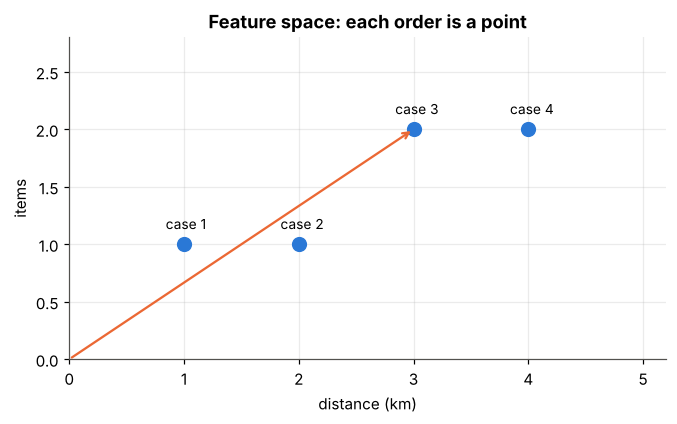

In [3]:
X = np.array([[1, 1], [2, 1], [3, 2], [4, 2]], dtype=float)   # one row per order

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(X[:, 0], X[:, 1], s=80, color=BLUE, zorder=3)
for i, (dist, items) in enumerate(X, start=1):
    ax.annotate(f"case {i}", (dist, items), xytext=(-12, 10), textcoords="offset points", fontsize=9)
ax.annotate("", xy=(3, 2), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=ORANGE, lw=1.5))
ax.set(xlabel="distance (km)", ylabel="items", xlim=(0, 5.2), ylim=(0, 2.8),
       title="Feature space: each order is a point")
plt.show()

The orange arrow draws the vector `[3, 2]` from the origin to case 3. The chart shows **features only**: the observed minutes are not on it.

**Three different things can look the same.** Keep their roles apart:

| Object | Example | Describes | Units |
| --- | --- | --- | --- |
| feature vector | `[3, 2]` | one order | km, items |
| weight vector | `[4, 2]` | the rule, shared by every order | minutes per km, minutes per item |
| target | `23` | the real outcome of one order | minutes |

The target is **never** an input. Feeding the answer into the rule would be cheating: the rule would "predict" what it was already told.

> **Why it matters for ML.** Every ML model receives its inputs as vectors. Counting carefully: **features = dimensions** (here 2), **orders = points** (here 4). Adding 1,000 more orders adds points; adding a feature such as "number of stops" adds a dimension, and each vector gets one more entry.

## Part 2 · Matrices: many orders, kept aligned

**Everyday example.** A spreadsheet of customers: one **row** per customer, one **column** per attribute. That table is a **matrix**. Its **shape** is (rows, columns).

We stack the four order vectors into a matrix `X`. The targets go in a separate vector `y`. The rule's weights go in `w`, and the base time is the scalar `b`.

In [4]:
y = np.array([15, 18, 23, 26], dtype=float)  # observed minutes, one per order
w = np.array([4, 2], dtype=float)            # [minutes per km, minutes per item]
b = 10.0                                     # base minutes

print("X shape:", X.shape, "-> 4 orders (rows), 2 features (columns)")
print("y shape:", y.shape, "  -> one target per order")
print("w shape:", w.shape, "  -> one weight per feature")
print("X[2]    =", X[2], "     -> row 2 = case 3")
print("X[:, 0] =", X[:, 0], "-> column 0 = all distances")

X shape: (4, 2) -> 4 orders (rows), 2 features (columns)
y shape: (4,)   -> one target per order
w shape: (2,)   -> one weight per feature
X[2]    = [3. 2.]      -> row 2 = case 3
X[:, 0] = [1. 2. 3. 4.] -> column 0 = all distances


`X[:, 0]` reads "all rows, column 0". Shapes are a built-in correctness check: `w` has **2** entries because `X` has **2 columns** (features), not because of anything to do with the 4 orders.

### Two ways to multiply: `*` and `@`

**Everyday example: a shopping basket.** You buy 3 loaves at R20 and 2 litres of milk at R25.

- **Line totals** (`*`, item by item): `[3, 2] * [20, 25] = [60, 50]`. You still see where the money went.
- **Bill total** (`@`, multiply then add): `[3, 2] @ [20, 25] = 60 + 50 = 110`. One number.

Our rule works the same way: features are the quantities and weights are the prices.

In [5]:
print("Basket: line totals", np.array([3, 2]) * np.array([20, 25]),
      "| bill", np.array([3, 2]) @ np.array([20, 25]), "\n")

print("X * w  (minutes from each feature, kept apart):")
print(X * w, " shape", (X * w).shape)
print("\nX @ w  (one weighted sum per order):", X @ w, " shape", (X @ w).shape)

Basket: line totals [60 50] | bill 110 

X * w  (minutes from each feature, kept apart):
[[ 4.  2.]
 [ 8.  2.]
 [12.  4.]
 [16.  4.]]  shape (4, 2)

X @ w  (one weighted sum per order): [ 6. 10. 16. 20.]  shape (4,)


`X * w` gives a **(4, 2)** breakdown: case 3 gets 12 minutes from distance and 4 from items. `X @ w` adds each row into **one number per order**, shape **(4,)**. Ask yourself which question you are answering: "where do the minutes come from?" uses `*`; "what is the total per order?" uses `@`.

**When is `@` allowed?** Write the shapes side by side. The **inner** numbers must match, and the **outer** numbers give the result's shape:

| Product | Shapes | Inner match? | Result |
| --- | --- | --- | --- |
| `X @ w` | (4, **2**) @ (**2**,) | 2 = 2 ✓ | (4,) |
| `X @ W` | (4, **2**) @ (**2**, 2) | 2 = 2 ✓ | (4, 2) |
| `X @ v3` | (4, **2**) @ (**3**,) | 2 ≠ 3 ✗ | error |

In [6]:
v3 = np.array([1.0, 2.0, 3.0])               # three weights for two features: wrong
try:
    X @ v3
except ValueError as err:
    print("ValueError:", str(err)[:95], "...")

W = np.array([[4, 5], [2, 2]], dtype=float)  # two rules side by side, one per column
print("\nX @ W (column 1: rule [4, 2], column 2: rule [5, 2]):\n", X @ W)
print("\nX.T (transpose) shape:", X.T.shape, "-> rows and columns swapped")

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k ...

X @ W (column 1: rule [4, 2], column 2: rule [5, 2]):
 [[ 6.  7.]
 [10. 12.]
 [16. 19.]
 [20. 24.]]

X.T (transpose) shape: (2, 4) -> rows and columns swapped


The error says 3 weights cannot pair with 2 features. **Fix the meaning, not the shape:** is a feature missing, or is there an extra weight? Don't reshape or transpose just to make the error disappear. Code that runs can still answer the wrong question.

> **Why it matters for ML.** Real datasets have thousands of rows and dozens of columns. One line, `X @ w`, applies the rule to every row at once, and shape checks catch most bugs before they produce silent nonsense.

## Part 3 · The dot product: from features to a prediction

The **dot product** multiplies matching entries and adds them up. For case 3:

| Feature | Value | × Weight | = Minutes |
| --- | --- | --- | --- |
| distance | 3 km | 4 min/km | 12 |
| items | 2 | 2 min/item | 4 |
| **dot product** | | | **16** |

Add the base time: 16 + 10 = **26 minutes** predicted. The record says 23. In symbols:

> **ŷ = x · w + b**   (ŷ, "y-hat", means *predicted*)

The weights (4 and 2) and the base (10) are the rule's **parameters**: shared by every order, and the numbers that learning will adjust.

case 3: dot product 16.0 -> prediction 26.0 minutes
all predictions: [16. 20. 26. 30.] | observed: [15. 18. 23. 26.]


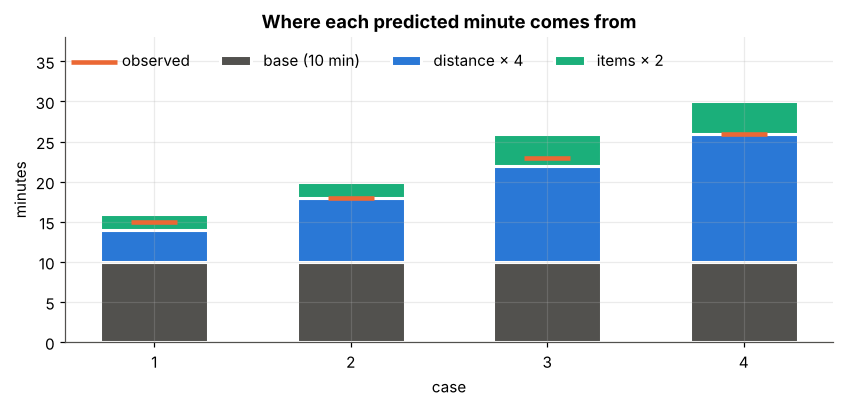

In [7]:
predictions = X @ w + b                      # the rule applied to all four orders at once
print("case 3: dot product", X[2] @ w, "-> prediction", X[2] @ w + b, "minutes")
print("all predictions:", predictions, "| observed:", y)

parts = {"base (10 min)": np.full(4, b), "distance × 4": X[:, 0] * w[0], "items × 2": X[:, 1] * w[1]}
fig, ax = plt.subplots(figsize=(9, 3.6))
bottom = np.zeros(4)
for (label, values), colour in zip(parts.items(), [MUTED, BLUE, AQUA]):
    ax.bar(range(1, 5), values, bottom=bottom, color=colour, width=0.55, label=label,
           edgecolor="white", linewidth=2)
    bottom += values
ax.scatter(range(1, 5), y, marker="_", s=900, color=ORANGE, linewidths=3, label="observed", zorder=5)
ax.set(xticks=range(1, 5), xlabel="case", ylabel="minutes", title="Where each predicted minute comes from")
ax.legend(frameon=False, loc="upper left", ncol=4)
ax.set_ylim(0, 38)
plt.show()

**Reading the chart.** Each bar is one prediction, split into its three parts. The orange line is what really happened. Every bar sits **above** its line: the rule over-predicts every order, and the gap grows with distance. That hints the minutes-per-km weight (4) is too high.

> **Why it matters for ML.** Linear regression, logistic regression and every neuron in a neural network start with the same step: features · weights + bias. The weight's size tells you how strongly a feature pushes the prediction, which is why stakeholders can read "4 minutes per km" directly.

## Part 4 · Loss: how wrong is the rule, in one number?

**Everyday example.** A weather forecaster predicts 25°C, 25°C and 30°C on three days; the real temperatures are 22, 28 and 30. To compare forecasters fairly you need **one score** that grows with every miss, whichever direction it points.

**Step 1: signed error** = predicted − observed. Positive means the rule over-predicts.

**Step 2: why square?** Errors of +3 and −3 average to 0, as if the rule were perfect. Squaring makes every miss count: (+3)² = (−3)² = 9. It also makes big misses cost much more than small ones.

**Step 3: mean squared error (MSE)** = the average of the squared errors. This score is called the **loss**.

In [8]:
errors = predictions - y                     # signed: predicted minus observed
mse = np.mean(errors ** 2)

print("errors:        ", errors)
print("squared errors:", errors ** 2)
print("average signed error:", errors.mean(), "(misleading if errors had mixed signs)")
print(f"MSE = {(errors ** 2).sum():.0f} / 4 = {mse} minutes²")

errors:         [1. 2. 3. 4.]
squared errors: [ 1.  4.  9. 16.]
average signed error: 2.5 (misleading if errors had mixed signs)
MSE = 30 / 4 = 7.5 minutes²


MSE = **7.5 minutes²**. Case 4 alone contributes 16 of the 30: the largest miss dominates. The unit is **squared minutes**, so 7.5 is a score for **comparing** rules, not "7.5 minutes late".

### Loss as a function of one parameter

To see the idea clearly, we hold the base (10) and the items weight (2) fixed and change only **a**, the minutes-per-km weight. Every choice of `a` gives different predictions, so a different loss. That makes the loss a **function** of `a`, written **L(a)**.

a = 2.0: predictions [14. 16. 20. 22.] -> loss 7.50
a = 3.0: predictions [15. 18. 23. 26.] -> loss 0.00
a = 4.0: predictions [16. 20. 26. 30.] -> loss 7.50
a = 5.0: predictions [17. 22. 29. 34.] -> loss 30.00


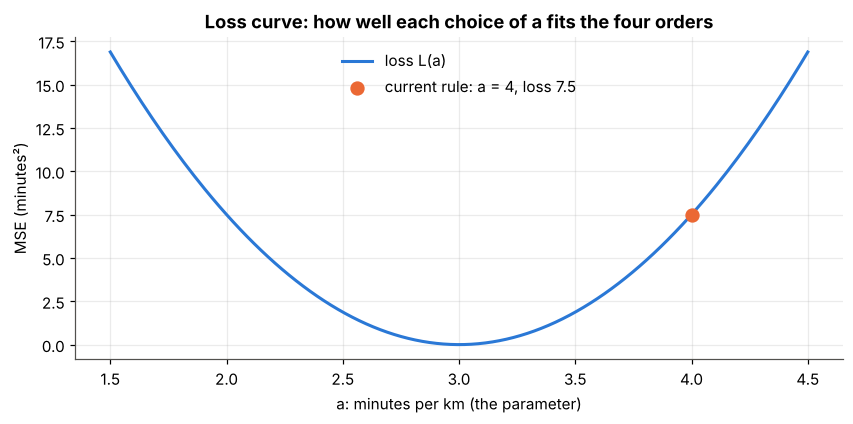

In [9]:
def predict(a):
    """Predicted minutes for the four orders when the distance weight is a."""
    return b + a * X[:, 0] + 2 * X[:, 1]

def loss(a):
    """Mean squared error (minutes²) of the rule with distance weight a."""
    return np.mean((predict(a) - y) ** 2)

for a in [2.0, 3.0, 4.0, 5.0]:
    print(f"a = {a}: predictions {predict(a)} -> loss {loss(a):.2f}")

a_grid = np.linspace(1.5, 4.5, 200)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(a_grid, [loss(a) for a in a_grid], color=BLUE, linewidth=2, label="loss L(a)")
ax.scatter(4, loss(4), color=ORANGE, s=70, zorder=5, label="current rule: a = 4, loss 7.5")
ax.set(xlabel="a: minutes per km (the parameter)", ylabel="MSE (minutes²)",
       title="Loss curve: how well each choice of a fits the four orders")
ax.legend(frameon=False)
plt.show()

**Reading the chart.** The horizontal axis is now a **parameter**, not a feature: this is a different kind of chart from the feature space in Part 1. The curve is U-shaped with its lowest point near a = 3, where the loss is 0. Our current rule (a = 4) sits on the right-hand slope.

> **Why it matters for ML.** "Training a model" means **finding the parameters with the lowest loss**. With one parameter we can draw the curve and see the answer. Real models have thousands or millions of parameters, and nobody can draw that. The next two parts show how to walk downhill without seeing the whole curve.

> **Watch out.** A low loss here is **training loss** on four invented orders. It says the rule fits *these* records, not that it will predict tomorrow's deliveries well. Checking on new data is the next session's topic.

## Part 5 · Slope, derivative and gradient: which way is downhill?

**Everyday example: lost on a hill in thick fog.** You can't see the valley, but you can feel the ground under your feet. If it tilts down to the left, step left. That local tilt is the **slope**. Gradient descent is exactly this: feel the slope, step downhill, repeat.

**Slope = change in output ÷ change in input**, measured over a tiny step. Take f(x) = x² at x = 2 and nudge x by a small amount h:

In [10]:
f = lambda x: x ** 2
for h in [1, 0.5, 0.1, 0.01, 0.001]:
    print(f"h = {h:<6} slope ≈ (f(2 + h) - f(2)) / h = {(f(2 + h) - f(2)) / h:.4f}")

h = 1      slope ≈ (f(2 + h) - f(2)) / h = 5.0000
h = 0.5    slope ≈ (f(2 + h) - f(2)) / h = 4.5000
h = 0.1    slope ≈ (f(2 + h) - f(2)) / h = 4.1000
h = 0.01   slope ≈ (f(2 + h) - f(2)) / h = 4.0100
h = 0.001  slope ≈ (f(2 + h) - f(2)) / h = 4.0010


As h shrinks, the ratio settles at **4**. That limit is the **derivative**: the slope at exactly x = 2. It is written **dL/da** ("how fast L changes as a changes").

| Slope | Meaning | To lower the loss, move the parameter... |
| --- | --- | --- |
| positive | loss rises as the parameter rises | **down** |
| negative | loss falls as the parameter rises | **up** |
| near zero | locally flat | barely |

**The rule to remember: move opposite to the sign of the slope.** A steeper slope (bigger size) means the loss changes fast there.

**The slope of our loss.** For L(a), the derivative has a simple formula:

> **g(a) = 2 × mean( distance × error )**

Each order's error is weighted by its distance (distance decides how strongly `a` affects that prediction), and the 2 comes from the square. We check the formula against the nudge method:

formula:      g(4) = 15.0000
nudge method: (L(4 + h) - L(4)) / h = 15.0000


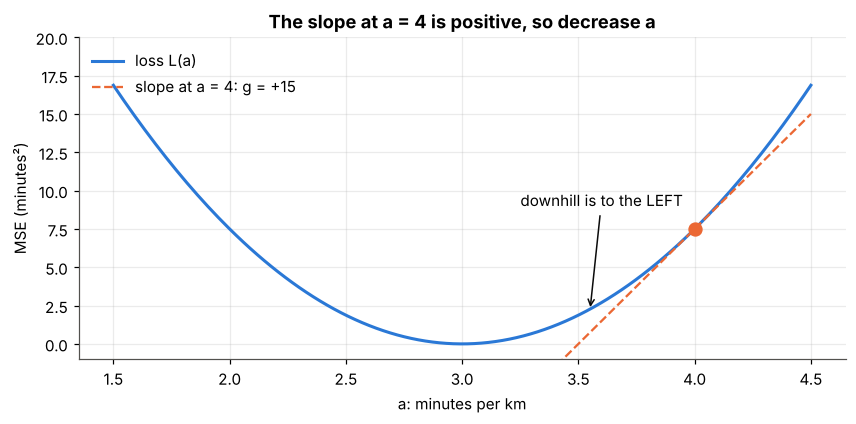

In [11]:
def gradient(a):
    """Slope of the loss L(a): 2 x mean(distance x signed error)."""
    return 2 * np.mean(X[:, 0] * (predict(a) - y))

h = 1e-6
print(f"formula:      g(4) = {gradient(4.0):.4f}")
print(f"nudge method: (L(4 + h) - L(4)) / h = {(loss(4 + h) - loss(4)) / h:.4f}")

a0 = 4.0
tangent = loss(a0) + gradient(a0) * (a_grid - a0)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(a_grid, [loss(a) for a in a_grid], color=BLUE, linewidth=2, label="loss L(a)")
ax.plot(a_grid, tangent, color=ORANGE, linestyle="--", label=f"slope at a = 4: g = +{gradient(a0):.0f}")
ax.scatter(a0, loss(a0), color=ORANGE, s=70, zorder=5)
ax.annotate("downhill is to the LEFT", xy=(3.55, 2.2), xytext=(3.6, 9),
            arrowprops=dict(arrowstyle="->", color=INK), ha="center")
ax.set(xlabel="a: minutes per km", ylabel="MSE (minutes²)", ylim=(-1, 20),
       title="The slope at a = 4 is positive, so decrease a")
ax.legend(frameon=False, loc="upper left")
plt.show()

At a = 4 the slope is **+15**: distances [1, 2, 3, 4] × errors [1, 2, 3, 4] = [1, 4, 9, 16], mean 7.5, × 2 = 15. Positive means uphill to the right, so we should **decrease** `a`. That matches the stacked bars in Part 3, which showed the rule charging too much per km.

**One slope per parameter = the gradient.** With several parameters (a, c, b), each has its own slope. The list of all of them is the **gradient vector**, written ∇L. It points uphill; **−∇L points downhill**. We use the one-parameter version here; Part 7 uses all three.

> **Why it matters for ML.** You never need to see the whole loss surface. The gradient, computed from the data at the current parameters, tells every parameter which way to move. Libraries such as PyTorch and TensorFlow compute these slopes automatically for millions of parameters.

## Part 6 · Gradient descent and the learning rate

**Everyday example: adjusting a shower.** Too hot? Turn the tap a little towards cold, wait, feel again. A tiny turn takes forever; a huge turn swings you from scalding to freezing and back. The size of each turn is the **learning rate**.

**The update rule:**

> **a_next = a − α × g**

- **g** is the slope at the current a (the direction information).
- **α** (alpha) is the **learning rate**: how big a step we take. We choose it, so it is a **hyperparameter**, not learned from the data.
- The **minus sign** sends `a` opposite to the slope: downhill.

**One step by hand:** a = 4, g = +15, α = 0.05 → step = 0.05 × 15 = 0.75 → **a_next = 3.25**.

In [12]:
alpha = 0.05
a1 = a0 - alpha * gradient(a0)
print(f"a: {a0} -> {a1} | loss: {loss(a0)} -> {loss(a1)} minutes²")
print("new predictions:", predict(a1), "| observed:", y)

a: 4.0 -> 3.25 | loss: 7.5 -> 0.46875 minutes²
new predictions: [15.25 18.5  23.75 27.  ] | observed: [15. 18. 23. 26.]


One step cut the loss from 7.5 to 0.47. Now repeat it: predict, compare, find the slope, update. Each pass is one **iteration**. **Iteration 0** is the starting point, before any update.

iteration 0: a = 4.000000  loss = 7.50000000
iteration 1: a = 3.250000  loss = 0.46875000
iteration 2: a = 3.062500  loss = 0.02929688
iteration 3: a = 3.015625  loss = 0.00183105
iteration 4: a = 3.003906  loss = 0.00011444
iteration 5: a = 3.000977  loss = 0.00000715
iteration 6: a = 3.000244  loss = 0.00000045
iteration 7: a = 3.000061  loss = 0.00000003


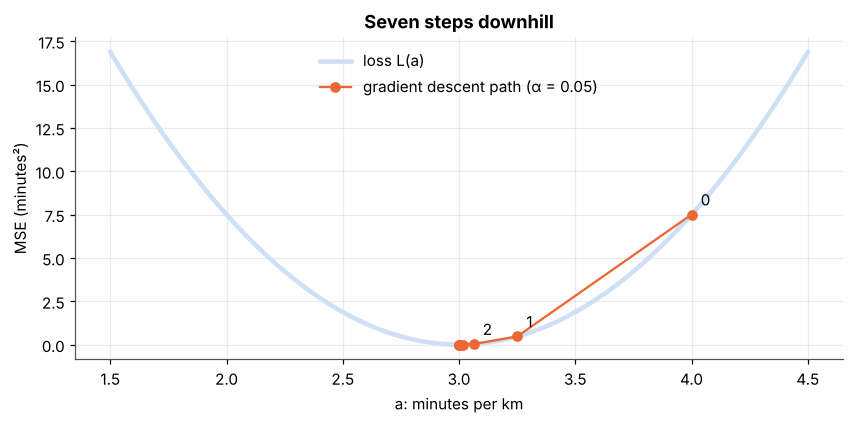

In [13]:
def gradient_descent(alpha, steps=7, start=4.0):
    """Run gradient descent on a; return the history of a and loss, including iteration 0."""
    a = start
    a_hist, loss_hist = [a], [loss(a)]
    for _ in range(steps):
        a = a - alpha * gradient(a)
        a_hist.append(a)
        loss_hist.append(loss(a))
    return np.array(a_hist), np.array(loss_hist)

a_hist, loss_hist = gradient_descent(alpha=0.05)
for i, (a, l) in enumerate(zip(a_hist, loss_hist)):
    print(f"iteration {i}: a = {a:.6f}  loss = {l:.8f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(a_grid, [loss(a) for a in a_grid], color=LIGHT_BLUE, linewidth=3, label="loss L(a)")
ax.plot(a_hist, loss_hist, "o-", color=ORANGE, label="gradient descent path (α = 0.05)")
for i in range(3):
    ax.annotate(str(i), (a_hist[i], loss_hist[i]), xytext=(6, 6), textcoords="offset points")
ax.set(xlabel="a: minutes per km", ylabel="MSE (minutes²)", title="Seven steps downhill")
ax.legend(frameon=False)
plt.show()

**Reading the output.** The first step is big because the slope is steep; later steps shrink by themselves as the ground flattens. After 7 updates, a ≈ 3.00006 and the loss is about 0.00000003: tiny but not exactly zero. The data were built from a true rate of **3 minutes per km**, and gradient descent found it **without ever seeing that number**.

### How the learning rate changes the path

Same start (a = 4), same data, same 7 steps; only α changes.

α = 0.001: a after 7 steps =    3.8996 | loss 7.5 -> 6.06972
α = 0.05 : a after 7 steps =    3.0001 | loss 7.5 -> 2.79397e-08
α = 0.2  : a after 7 steps = -125.0000 | loss 7.5 -> 122,880


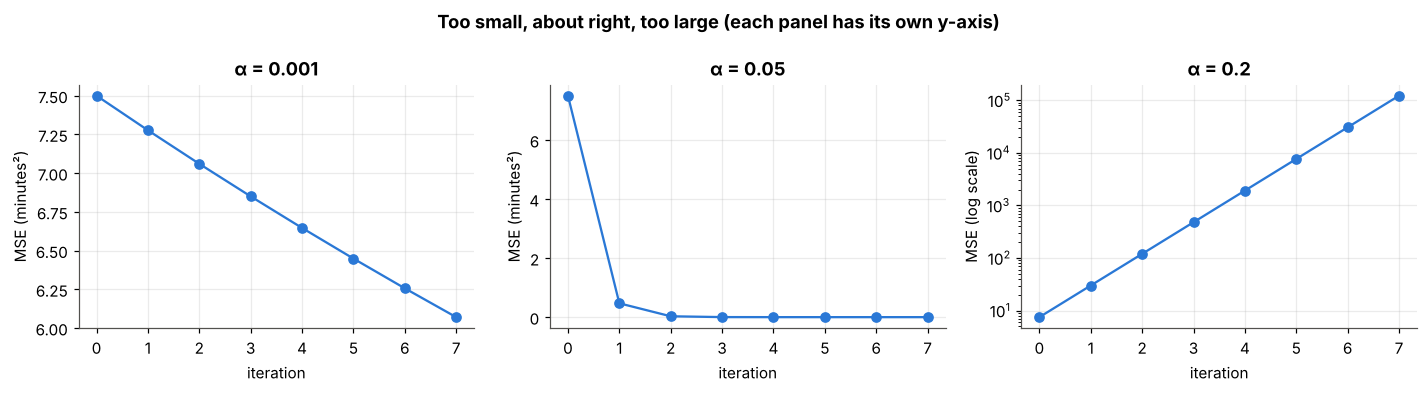

In [14]:
rates = [0.001, 0.05, 0.20]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, rate in zip(axes, rates):
    a_h, l_h = gradient_descent(rate)
    print(f"α = {rate:<5}: a after 7 steps = {a_h[-1]:>9.4f} | loss {l_h[0]} -> {l_h[-1]:,.6g}")
    ax.plot(range(8), l_h, "o-", color=BLUE)
    ax.set(title=f"α = {rate}", xlabel="iteration", ylabel="MSE (minutes²)")
    if rate == 0.20:
        ax.set_yscale("log")
        ax.set_ylabel("MSE (log scale)")
fig.suptitle("Too small, about right, too large (each panel has its own y-axis)", fontweight="bold")
fig.tight_layout()
plt.show()

| α | What happened | Shower version |
| --- | --- | --- |
| 0.001 | creeps: loss only falls from 7.5 to 6.07 in 7 steps | turning the tap a hair at a time |
| 0.05 | drops fast and settles at the minimum | sensible turns |
| 0.20 | each step overshoots further: a ends at −125, loss explodes to 122,880 | yanking the tap: scalding, freezing, worse each time |

Overshooting the bottom once is not automatically a failure: with α = 0.09 the first step lands on the other side (a = 2.65), then the swings shrink and it still settles. A run **diverges** only when each landing is higher than the last.

> **Why it matters for ML.** The learning rate is one of the most important settings when training any model. Too small wastes compute time; too large makes training blow up (in code you will see `inf` or `nan`). Watching the loss-per-iteration chart is the standard way to diagnose it.

## Part 7 · Going further: all parameters, realistic data

The four-order example was built to be perfectly clean. Real data are noisy. Here we simulate **200 orders** whose true times follow 10 + 3 × distance + 2 × items **plus random noise** (traffic, waiting at the door). Then we start from a rule that knows **nothing** (all parameters 0) and let gradient descent learn **all three** parameters at once.

The only change from Part 6: the gradient is now a **vector**, one slope per parameter.

- slope for the weights w: 2 × Xᵀ(error) ÷ n (one entry per feature)
- slope for the base b: 2 × mean(error)

gradient descent: base 9.24 min | 3.07 min/km | 2.07 min/item
exact solver:     base 9.24 min | 3.07 min/km | 2.07 min/item
true rule:        base 10.00 min | 3.00 min/km | 2.00 min/item
training MSE: start 1,944 -> end 8.97 minutes²


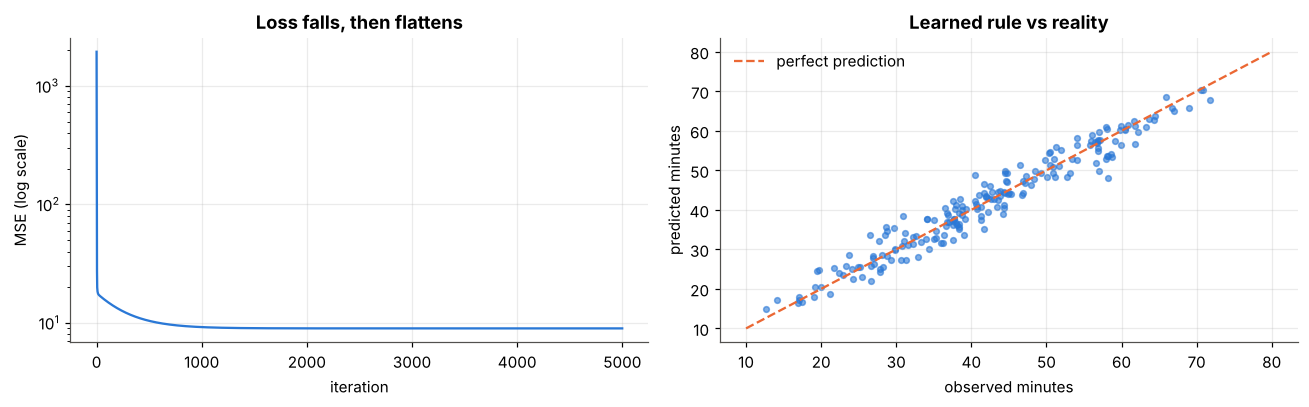

In [15]:
rng = np.random.default_rng(17)
n = 200
distance = rng.uniform(1, 15, n).round(1)
items = rng.integers(1, 9, n)
X_big = np.column_stack([distance, items]).astype(float)
y_big = 10 + 3 * distance + 2 * items + rng.normal(0, 3, n)       # true rule + noise

w_fit, b_fit, alpha = np.zeros(2), 0.0, 0.008                       # start knowing nothing
history = []
for step in range(5000):
    error = X_big @ w_fit + b_fit - y_big
    history.append(np.mean(error ** 2))
    w_fit -= alpha * 2 * X_big.T @ error / n                       # gradient for the 2 weights
    b_fit -= alpha * 2 * error.mean()                              # gradient for the base

exact = np.linalg.lstsq(np.column_stack([np.ones(n), X_big]), y_big, rcond=None)[0]
print(f"gradient descent: base {b_fit:.2f} min | {w_fit[0]:.2f} min/km | {w_fit[1]:.2f} min/item")
print(f"exact solver:     base {exact[0]:.2f} min | {exact[1]:.2f} min/km | {exact[2]:.2f} min/item")
print(f"true rule:        base 10.00 min | 3.00 min/km | 2.00 min/item")
print(f"training MSE: start {history[0]:,.0f} -> end {history[-1]:.2f} minutes²")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(history, color=BLUE)
axes[0].set(yscale="log", xlabel="iteration", ylabel="MSE (log scale)", title="Loss falls, then flattens")
axes[1].scatter(y_big, X_big @ w_fit + b_fit, s=14, color=BLUE, alpha=0.6)
axes[1].plot([10, 80], [10, 80], color=ORANGE, linestyle="--", label="perfect prediction")
axes[1].set(xlabel="observed minutes", ylabel="predicted minutes", title="Learned rule vs reality")
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

**Reading the output.** Starting from zero, gradient descent learns a base of about 9.2 minutes, **3.07 minutes per km** and **2.07 minutes per item**: the same answer as NumPy's exact solver and close to the true rule. It is not exact because of the noise. The loss stops near **9 minutes²**, not 0: that leftover is the random noise (SD 3 → variance 9) that no rule using only distance and items can explain. In the right-hand chart, the points scatter around the dashed line instead of sitting on it, for the same reason.

> **Business meaning.** The learned rule tells the operations team their old rule over-charged about 1 minute per km (4 → 3.07). More accurate quotes mean customers are no longer put off by over-long estimates at checkout. But a fit on past orders is not proof of future accuracy: next session covers holding back data to test the rule on orders it has never seen.

> **Why it matters for ML.** This loop **is** linear regression trained by gradient descent. Neural networks use the identical recipe (predict, loss, gradient, update) with millions of parameters.

## Summary: the whole chain

| Question | Maths idea | In the delivery example |
| --- | --- | --- |
| What describes one order? | feature vector | `[3, 2]`: 3 km, 2 items |
| How do many orders stay aligned? | matrix | `X`, shape (4, 2) |
| How do features become one prediction? | dot product | x · w + b = 26 minutes |
| How wrong is the rule? | error, MSE (loss) | 7.5 minutes² |
| Which way should a parameter move? | slope, derivative, gradient | g = +15 at a = 4, so decrease a |
| How do we move? | gradient descent | a ← a − α × g |
| How big a step? | learning rate | 0.001 slow · 0.05 good · 0.20 diverges |

### Check your understanding

1. `X` has 4 rows and 2 columns. Why does `X @ w` give 4 numbers, not 8?
2. One order's error is +4 and another's is −4. Their average is 0. Is the rule perfect?
3. The slope at the current parameter is −6. Does the update increase or decrease it?
4. A run crosses the bottom of the loss curve on its first step. Has it failed?
5. The training loss is almost zero. Can we deploy the rule to customers?
6. Why can't `observed_minutes` be a third column of `X`?

In [16]:
# Try it: change the starting value, the learning rate (e.g. 0.09) or the number of steps,
# rerun gradient_descent(...) and describe what happens to the path.

### Answers

1. Each of the 4 rows makes **one** dot product with the 2 weights; `*` would keep both parts and give (4, 2).
2. No. Both orders are 4 minutes off; squaring makes both count, so the MSE is 16.
3. It **increases**: a − α × (−6) adds a positive amount. Move opposite to the slope's sign.
4. Not necessarily. Check the later losses: if they keep shrinking (like α = 0.09), it is settling. Only growing losses mean divergence.
5. No. Training loss shows fit to known orders, not accuracy on new ones. Optimising is not evaluating.
6. It is the answer we want to predict. Feeding it in hands the rule the answer, so the "prediction" would be meaningless.

**Next session:** framing a real ML problem as features and a target, and checking a model fairly on data it has not seen.

*All delivery data are synthetic: 4 hand-built orders and 200 simulated orders (seed 17).*